# 01 - Warehouse and SQL showcase
**Growth Experimentation Platform.** The data is a *simulated* grocery-delivery app (100,000 users, 84 days), so every
number here describes the simulator, not a real business. Each section runs one SQL file from `sql/analysis/`;
every one of those files has a test in `tests/sql/` that checks it against a hand-computed answer.

Run `python -m src.simulation.simulate` and `python -m src.warehouse.build_warehouse` first (the setup notebook does this).

In [1]:
import os, sys, pathlib
root = pathlib.Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from src.config import DB_PATH
from src.warehouse.run_sql import run_query

pd.set_option("display.width", 160, "display.max_columns", 20)
con = duckdb.connect(str(DB_PATH), read_only=True)
print("project root:", root, "| database:", DB_PATH)

project root: /content/drive/MyDrive/growth-experimentation-platform | database: /content/gep_work/experimentation.duckdb


## 1. What is in the warehouse

In [2]:
tables = [t for (t,) in con.execute("SHOW TABLES").fetchall()]
pd.DataFrame({"table": tables, "rows": [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables]})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,rows
0,assignments,852319
1,events,5275310
2,experiments,9
3,orders,90132
4,products,300
5,sessions,1540479
6,stg_events_clean,5243847
7,users,100000


## 2. Data quality first (staging layer)
`staging/stg_events_clean.sql` removes exact duplicate events (`ROW_NUMBER` over identical keys) and flags events that arrive
more than a day late. Everything downstream reads the clean view. The monitor below should be flat over time; a jump would mean a pipeline problem.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

duplicates removed: 0.60% of raw events | late (>1 day): 1.51% of distinct events


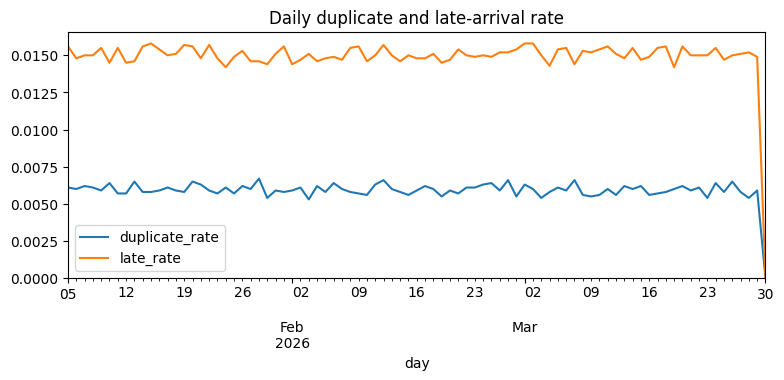

In [3]:
dq = run_query(con, "data_quality_events")
raw, distinct = dq.raw_events.sum(), dq.distinct_events.sum()
print(f"duplicates removed: {(raw - distinct) / raw:.2%} of raw events | late (>1 day): {dq.late_events.sum() / distinct:.2%} of distinct events")
ax = dq.set_index("day")[["duplicate_rate", "late_rate"]].plot(figsize=(9, 3.2), title="Daily duplicate and late-arrival rate")
ax.set_ylim(0); plt.show()

## 3. Purchase funnel by device (conditional aggregation on de-duplicated events)

In [4]:
run_query(con, "funnel_by_device")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,device,sessions,cart_rate,cart_to_checkout,checkout_to_purchase,session_conversion
0,android,887922,0.2234,0.5477,0.4822,0.0590
1,ios,469234,0.2234,0.5480,0.5422,0.0664
2,web,183323,0.2248,0.5491,0.2922,0.0361


## 4. Cohort retention (new users only)

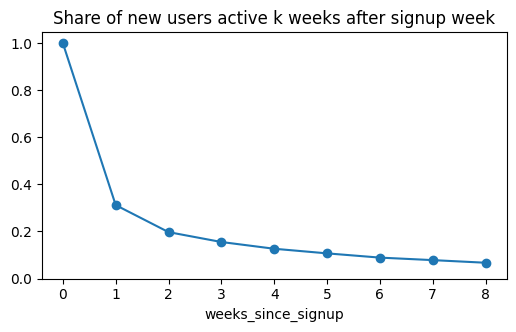

,retention
weeks_since_signup,
0,1.000
1,0.312
2,0.197
3,0.155
4,0.127
5,0.107
6,0.089
7,0.078
8,0.067


In [5]:
ret = run_query(con, "weekly_retention")
agg = ret.groupby("weeks_since_signup").agg(active=("active_users", "sum"), size=("cohort_size", "sum"))
curve = agg.active / agg["size"]
ax = curve.plot(marker="o", figsize=(6, 3.2), title="Share of new users active k weeks after signup week")
ax.set_ylim(0); plt.show()
curve.round(3).to_frame("retention")

## 5. Sessionization with `LAG` (rebuild sessions from raw events)
A new session starts when the gap to the user's previous event exceeds 30 minutes. The ratio below is rebuilt / logged sessions:
below 1 means some logged sessions started within 30 minutes of the previous one for the same user.

In [6]:
run_query(con, "sessionization_check")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,device,logged_sessions,rebuilt_sessions,rebuilt_to_logged_ratio
0,android,887922.0,873646.0,0.9839
1,ios,469234.0,461556.0,0.9836
2,web,183323.0,180420.0,0.9842


## 6. Window functions on a daily series (running total, moving average, day-over-day, week-over-week)

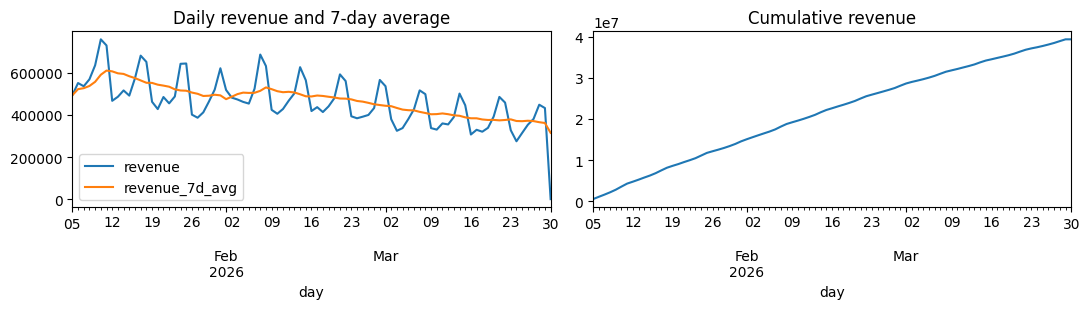

,day,orders,revenue,cumulative_revenue,revenue_7d_avg,dod_change,wow_change
0,2026-01-05,1166,492893.37,492893.37,492893.37,NaN,NaN
1,2026-01-06,1237,550832.69,1043726.06,521863.03,0.1175,NaN
2,2026-01-07,1228,535653.84,1579379.90,526459.97,-0.0276,NaN
3,2026-01-08,1316,568543.77,2147923.67,536980.92,0.0614,NaN
4,2026-01-09,1442,634874.06,2782797.73,556559.55,0.1167,NaN
5,2026-01-10,1771,758114.16,3540911.89,590151.98,0.1941,NaN
6,2026-01-11,1682,728978.56,4269890.45,609984.35,-0.0384,NaN
7,2026-01-12,1106,466561.53,4736451.98,606222.66,-0.3600,-0.0534
8,2026-01-13,1100,485772.68,5222224.66,596928.37,0.0412,-0.1181
9,2026-01-14,1217,515779.10,5738003.76,594089.12,0.0618,-0.0371


In [7]:
daily = run_query(con, "daily_revenue_trends")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
daily.set_index("day")[["revenue", "revenue_7d_avg"]].plot(ax=ax[0], title="Daily revenue and 7-day average")
daily.set_index("day")["cumulative_revenue"].plot(ax=ax[1], title="Cumulative revenue"); plt.tight_layout(); plt.show()
daily.head(10)

## 7. Top-N per group (`DENSE_RANK` + `QUALIFY`): most carted products per category

In [8]:
run_query(con, "top_products_per_category").head(12)

,category,product_id,cart_adds,rank_in_category
0,bakery,125,5325,1
1,bakery,141,3304,2
2,bakery,217,2722,3
3,beverages,165,8125,1
4,beverages,82,5054,2
5,beverages,276,4883,3
6,dairy,284,9704,1
7,dairy,40,3990,2
8,dairy,214,3626,3
9,fruits_veg,286,10461,1


## 8. RFM segmentation in SQL (`NTILE`)
Recency, frequency and monetary value are each scored 1-5; segments come from readable rules. Segment names here are rule outputs on simulated data.

In [9]:
run_query(con, "rfm_segments")

,segment,users,avg_recency_days,avg_orders,avg_revenue,share_of_revenue
0,champions,9608,11.7,4.42,2065.59,0.5042
1,loyal,7805,28.4,2.39,1011.94,0.2006
2,at_risk,6479,62.3,2.02,865.94,0.1425
3,lost,9449,67.7,1.00,378.03,0.0907
4,new_or_promising,3637,13.8,1.00,368.73,0.0341
5,needs_attention,2842,36.8,1.00,385.40,0.0278


## 9. Gaps and islands: longest run of consecutive active days per user

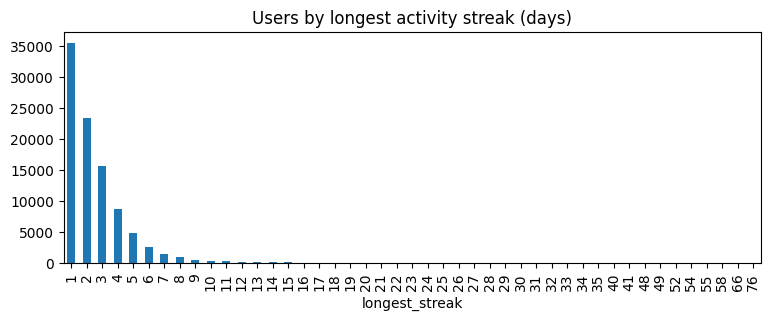

In [10]:
st = run_query(con, "activity_streaks")
st.set_index("longest_streak").users.plot.bar(figsize=(9, 3), title="Users by longest activity streak (days)"); plt.show()

## What this notebook does and does not show
It shows working, tested SQL for funnels, cohorts, sessionization, window functions, top-N, RFM, streaks and data-quality monitoring on a
100k-user simulated dataset in DuckDB. It does **not** show query tuning, large-scale performance, or behaviour on a real warehouse.